# E-commerce Churn Prediction

## Project Summary
This project analyzes and predicts customer churn behavior for an e-commerce business.
The main objective is to identify churn drivers, build a churn prediction model, segment churned customers, and propose actionable retention strategies.

## Workflow
1. Data Understanding and Cleaning
2. Exploratory Data Analysis (EDA)
3. Feature Engineering and Preprocessing
4. Supervised Learning: Churn Prediction
5. Model Evaluation and Feature Importance
6. Unsupervised Learning: Churned Customer Segmentation
7. Cluster Profiling
8. Business Insights and Recommendations


In [1]:
import sys
print(sys.executable)

C:\Users\ADITYA SINGH\Downloads\Advanced ML Assignment\Customer-Churn-Analysis\venv\Scripts\python.exe


## Notebook Structure Note
Each workflow step and sub-step has been separated into its own code cell. Run the notebook from top to bottom to preserve variable dependencies.


In [ ]:
# -*- coding: utf-8 -*-


## 0. Import Libraries And Configuration


In [ ]:
import warnings
warnings.filterwarnings("ignore")

import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, silhouette_score, classification_report, confusion_matrix
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans


## 1. Data Understanding And Cleaning


### 1.1 Download and load dataset


In [ ]:
# Dataset link:
# https://drive.google.com/file/d/165QbItaKjvDXie3vNA-95IIdoPak8d2U/view?usp=drive_link

try:
    import gdown
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "gdown"])
    import gdown

file_id = "1yxgr0Qj3TiXRehYa0PED1t4zIga9gdY5"
output_file = "churn_prediction.xlsx"
gdown.download(id=file_id, output=output_file, quiet=False)

data = pd.read_excel(output_file)


Downloading...
From: https://drive.google.com/uc?id=1yxgr0Qj3TiXRehYa0PED1t4zIga9gdY5
To: /content/churn_prediction.xlsx
100%|██████████| 494k/494k [00:00<00:00, 58.4MB/s]


### 1.2 Initial data inspection


In [ ]:
print("Dataset shape:", data.shape)
print("\nDataset information:")
data.info()

print("\nNumber of duplicate rows:", data.duplicated().sum())
print("\nMissing values before cleaning:")
print(data.isnull().sum())


Dataset shape: (5630, 20)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   object 
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   object 
 7   Gender                       5630 non-null   object 
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   object 
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus               

In [ ]:
# Display the number of unique values for each column in the dataset.
# This helps in understanding the cardinality of features.
print("Number of unique values for each column:")
print(data.nunique())

# Define a list of categorical columns to inspect for unique values.
# These columns are often good candidates for standardization or one-hot encoding.
columns_to_inspect_unique = [
    'PreferredLoginDevice', 'CityTier', 'PreferredPaymentMode',
    'PreferedOrderCat', 'SatisfactionScore', 'MaritalStatus', 'Complain'
]

# Iterate through the selected columns and print their unique values.
# This step helps to identify inconsistencies, typos, or variations in categorical data.
print("\n--- Unique Values Inspection for Categorical Columns ---")
for col in columns_to_inspect_unique:
    print(f"Unique values for '{col}':")
    print(data[col].unique())
    print("\n")

# Standardize values in 'PreferredLoginDevice' column.
# 'Phone' is replaced with 'Mobile Phone' for consistency.
data['PreferredLoginDevice'] = data['PreferredLoginDevice'].replace({'Phone': 'Mobile Phone'})
print(f"Standardized 'PreferredLoginDevice' unique values: {data['PreferredLoginDevice'].unique()}")

# Standardize values in 'PreferredPaymentMode' column.
# 'COD' is replaced with 'Cash on Delivery' and 'CC' with 'Credit Card' for consistency.
data['PreferredPaymentMode'] = data['PreferredPaymentMode'].replace({'COD': 'Cash on Delivery', 'CC': 'Credit Card'})
print(f"Standardized 'PreferredPaymentMode' unique values: {data['PreferredPaymentMode'].unique()}")

# Standardize values in 'PreferedOrderCat' column.
# 'Mobile' is replaced with 'Mobile Phone' for consistency.
data['PreferedOrderCat'] = data['PreferedOrderCat'].replace({'Mobile': 'Mobile Phone'})
print(f"Standardized 'PreferedOrderCat' unique values: {data['PreferedOrderCat'].unique()}")

# Re-check and print the total number of duplicate rows in the dataset after cleaning.
# This ensures that no new duplicates were introduced and confirms the current state.
print(f"\nNumber of duplicate rows after standardization: {data.duplicated().sum()}")

Number of unique values for each column:
CustomerID                     5630
Churn                             2
Tenure                           36
PreferredLoginDevice              3
CityTier                          3
WarehouseToHome                  34
PreferredPaymentMode              7
Gender                            2
HourSpendOnApp                    6
NumberOfDeviceRegistered          6
PreferedOrderCat                  6
SatisfactionScore                 5
MaritalStatus                     3
NumberOfAddress                  15
Complain                          2
OrderAmountHikeFromlastYear      16
CouponUsed                       17
OrderCount                       16
DaySinceLastOrder                22
CashbackAmount                 2586
dtype: int64

--- Unique Values Inspection for Categorical Columns ---
Unique values for 'PreferredLoginDevice':
['Mobile Phone' 'Computer' 'Phone']


Unique values for 'CityTier':
[3 1 2]


Unique values for 'PreferredPaymentMode':
['E wa

### 1.3 Handle missing values


In [ ]:
# Drop rows where Tenure is missing because Tenure is an important behavioral feature.
data.dropna(subset=["Tenure"], inplace=True)
print("\nShape after dropping rows with missing Tenure:", data.shape)

# Fill missing numerical values using the median to reduce the impact of outliers.
median_impute_cols = ["HourSpendOnApp", "CouponUsed", "OrderCount", "DaySinceLastOrder"]
for col in median_impute_cols:
    if col in data.columns:
        data[col].fillna(data[col].median(), inplace=True)

print("\nMissing values after imputation:")
print(data.isnull().sum())



Shape after dropping rows with missing Tenure: (5366, 20)

Missing values after imputation:
CustomerID                       0
Churn                            0
Tenure                           0
PreferredLoginDevice             0
CityTier                         0
WarehouseToHome                251
PreferredPaymentMode             0
Gender                           0
HourSpendOnApp                   0
NumberOfDeviceRegistered         0
PreferedOrderCat                 0
SatisfactionScore                0
MaritalStatus                    0
NumberOfAddress                  0
Complain                         0
OrderAmountHikeFromlastYear    265
CouponUsed                       0
OrderCount                       0
DaySinceLastOrder                0
CashbackAmount                   0
dtype: int64


### 1.4 Drop unnecessary columns


In [ ]:
# CustomerID is only an identifier and does not contribute to modeling.
# WarehouseToHome and OrderAmountHikeFromlastYear are removed based on project scope.
exclude_cols = ["CustomerID", "WarehouseToHome", "OrderAmountHikeFromlastYear"]
data.drop(columns=exclude_cols, inplace=True, errors="ignore")

print("\nData preview after cleaning:")
print(data.head(2))



Data preview after cleaning:
   Churn  Tenure PreferredLoginDevice  CityTier PreferredPaymentMode  Gender  \
0      0    20.0         Mobile Phone         3             E wallet  Female   
1      0    13.0             Computer         1     Cash on Delivery  Female   

   HourSpendOnApp  NumberOfDeviceRegistered PreferedOrderCat  \
0             4.0                         4          Fashion   
1             4.0                         4          Fashion   

   SatisfactionScore MaritalStatus  NumberOfAddress  Complain  CouponUsed  \
0                  5       Married                3         0         5.0   
1                  3        Single                2         0        11.0   

   OrderCount  DaySinceLastOrder  CashbackAmount  
0        16.0                3.0          229.53  
1         2.0                9.0          234.38  


## 2. Exploratory Data Analysis (Eda)


### 2.1 Distribution of numerical features


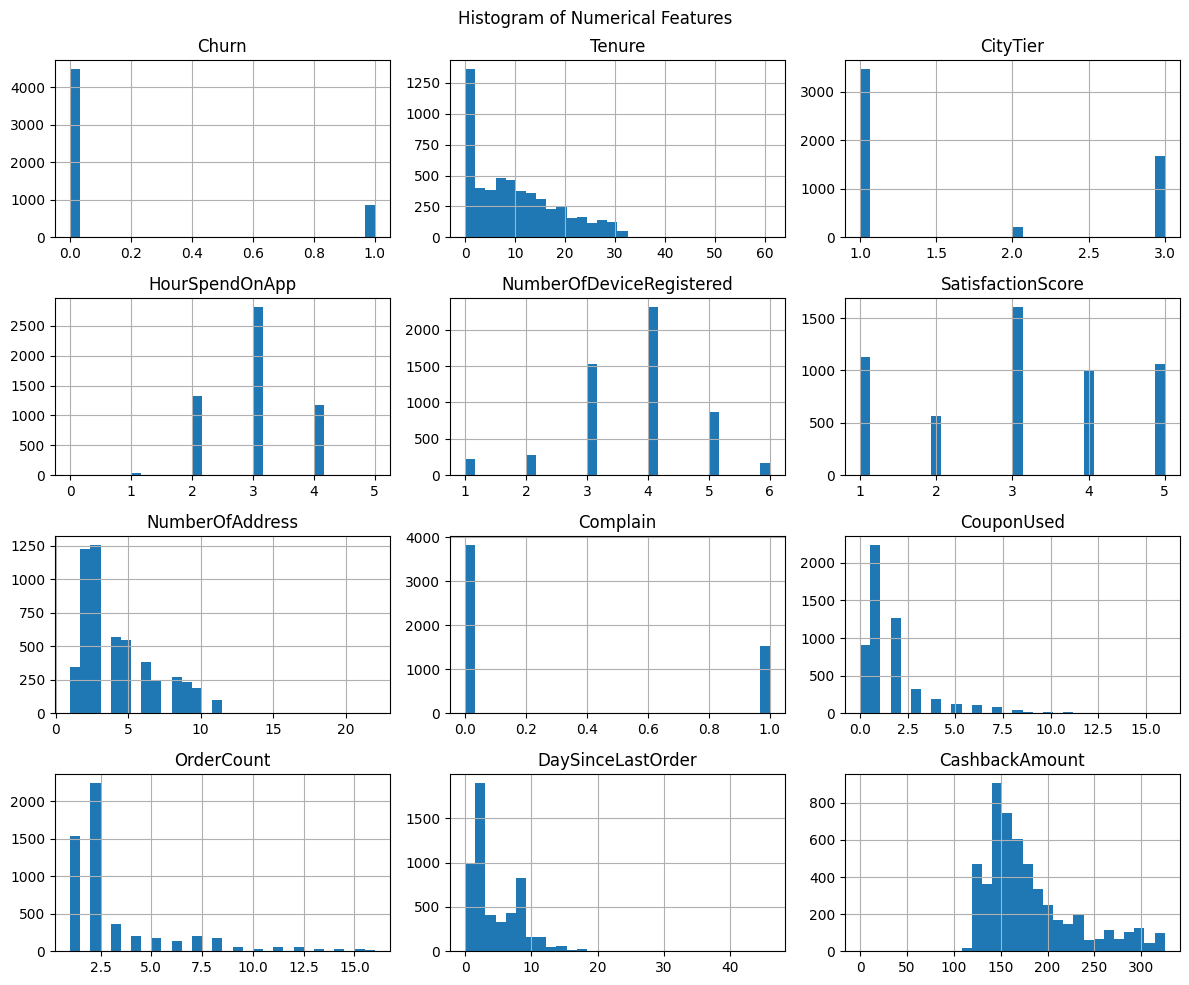

In [ ]:
numeric_cols = data.select_dtypes(include=["int64", "float64"]).columns

data[numeric_cols].hist(figsize=(12, 10), bins=30)
plt.suptitle("Histogram of Numerical Features")
plt.tight_layout()
plt.show()



EDA observations from numerical distributions:
- Churn is strongly skewed toward 0, meaning most customers did not churn.
- Tenure is right-skewed, showing that many customers have short engagement periods.
- CityTier has three clear groups, with CityTier 1 and 3 appearing more frequently.
- HourSpendOnApp is concentrated around 2 to 3 hours, indicating moderate app usage.
- NumberOfDeviceRegistered and NumberOfAddress decrease gradually, meaning most customers register only a few devices or addresses.
- SatisfactionScore is relatively evenly distributed from 1 to 5.
- Complain is mostly 0, but customers who complain may have higher churn risk.
- CouponUsed is right-skewed, meaning most customers use only a small number of coupons.
- CashbackAmount is concentrated around 100 to 200, which may reflect the company's common cashback policy.


### 2.2 Boxplots for outlier detection


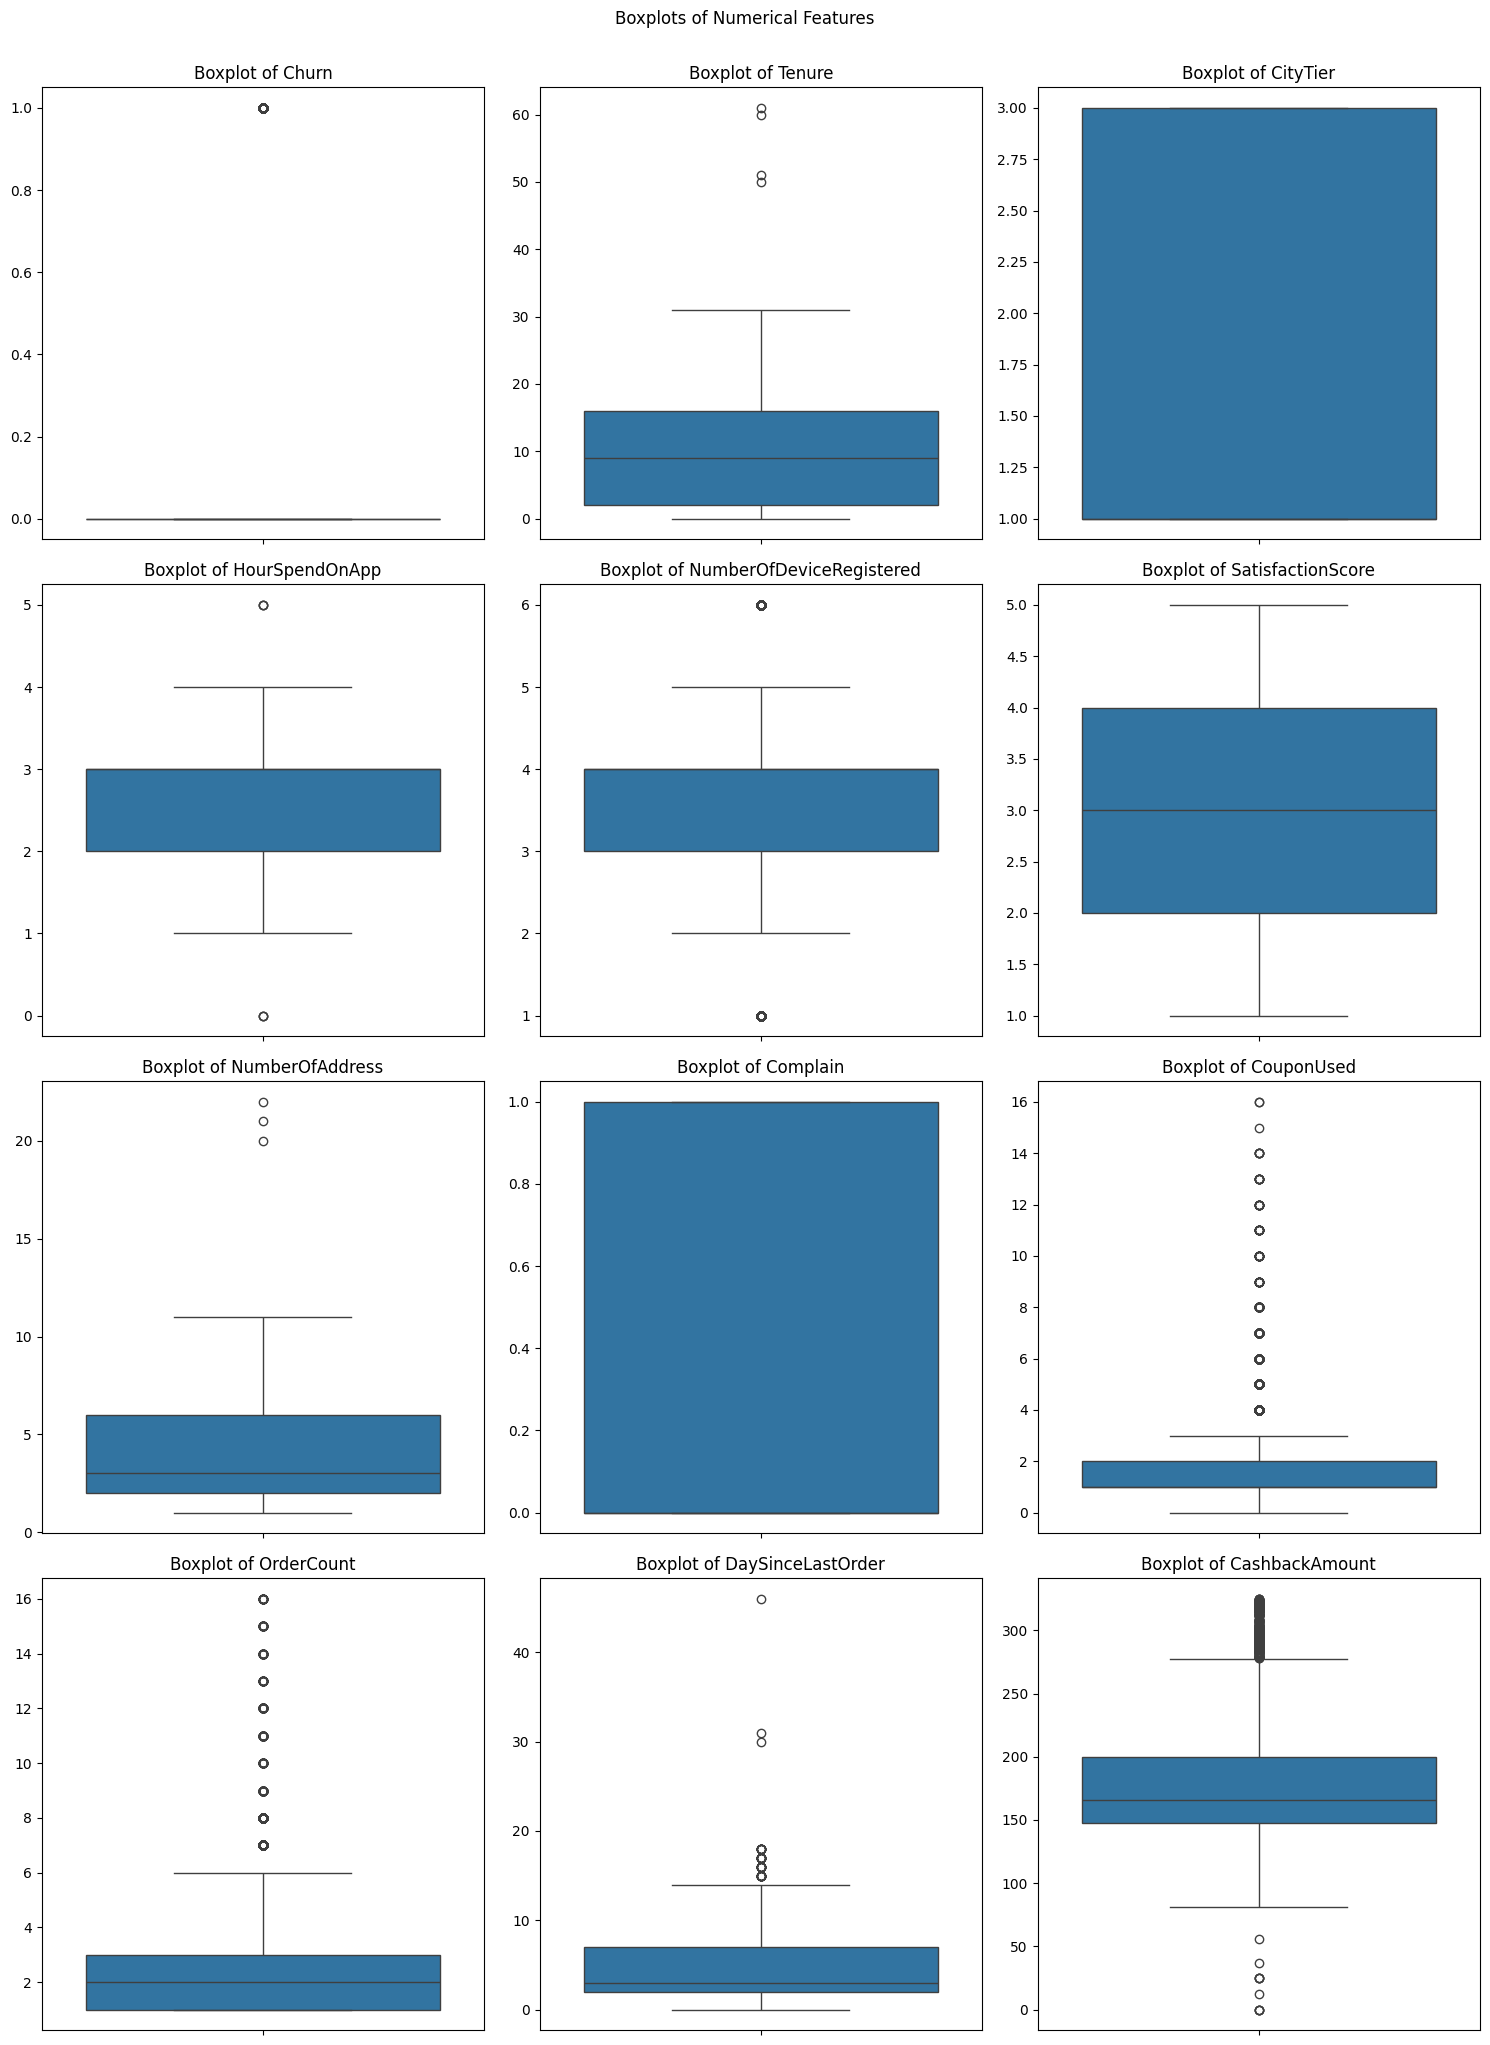

In [ ]:
num_cols_count = len(numeric_cols)
num_rows = (num_cols_count + 2) // 3

plt.figure(figsize=(15, 5 * num_rows))
for i, col in enumerate(numeric_cols):
    plt.subplot(num_rows, 3, i + 1)
    sns.boxplot(y=data[col])
    plt.title(f"Boxplot of {col}")
    plt.ylabel("")

plt.tight_layout()
plt.suptitle("Boxplots of Numerical Features", y=1.02)
plt.show()





Outlier decision:
The detected outliers are kept because they may represent meaningful customer behaviors rather than data errors.


### 2.3 Correlation heatmap


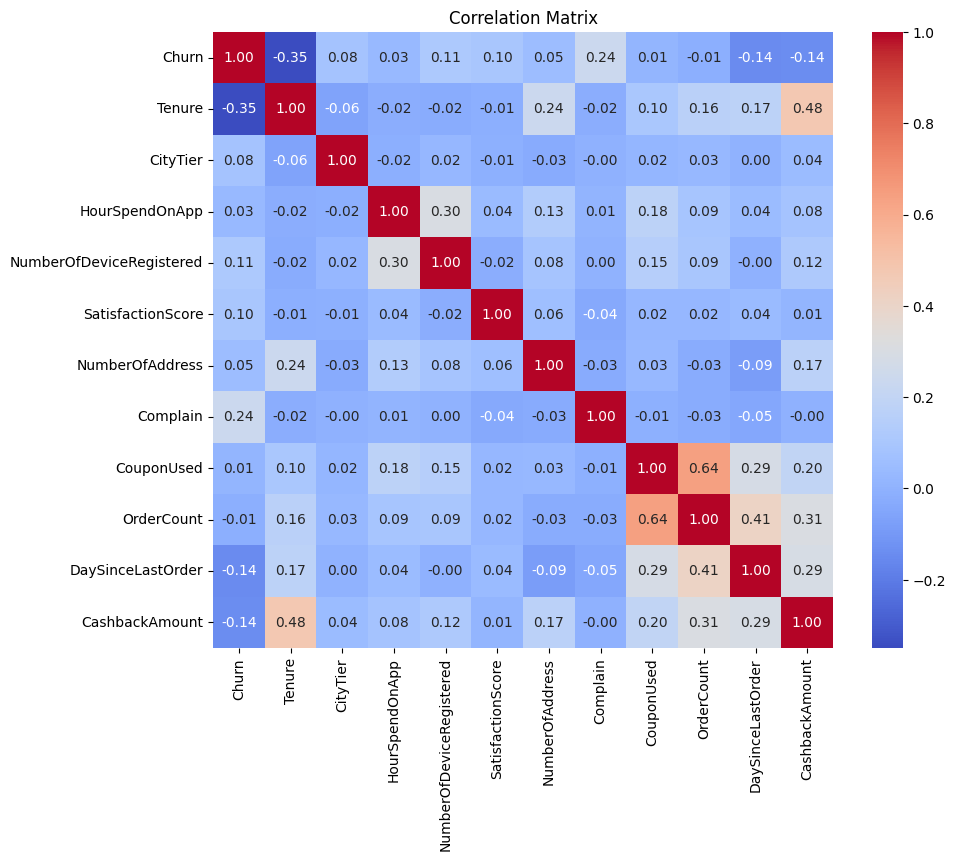

In [ ]:
corr = data[numeric_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()


### 2.4 Churn distribution by categorical features


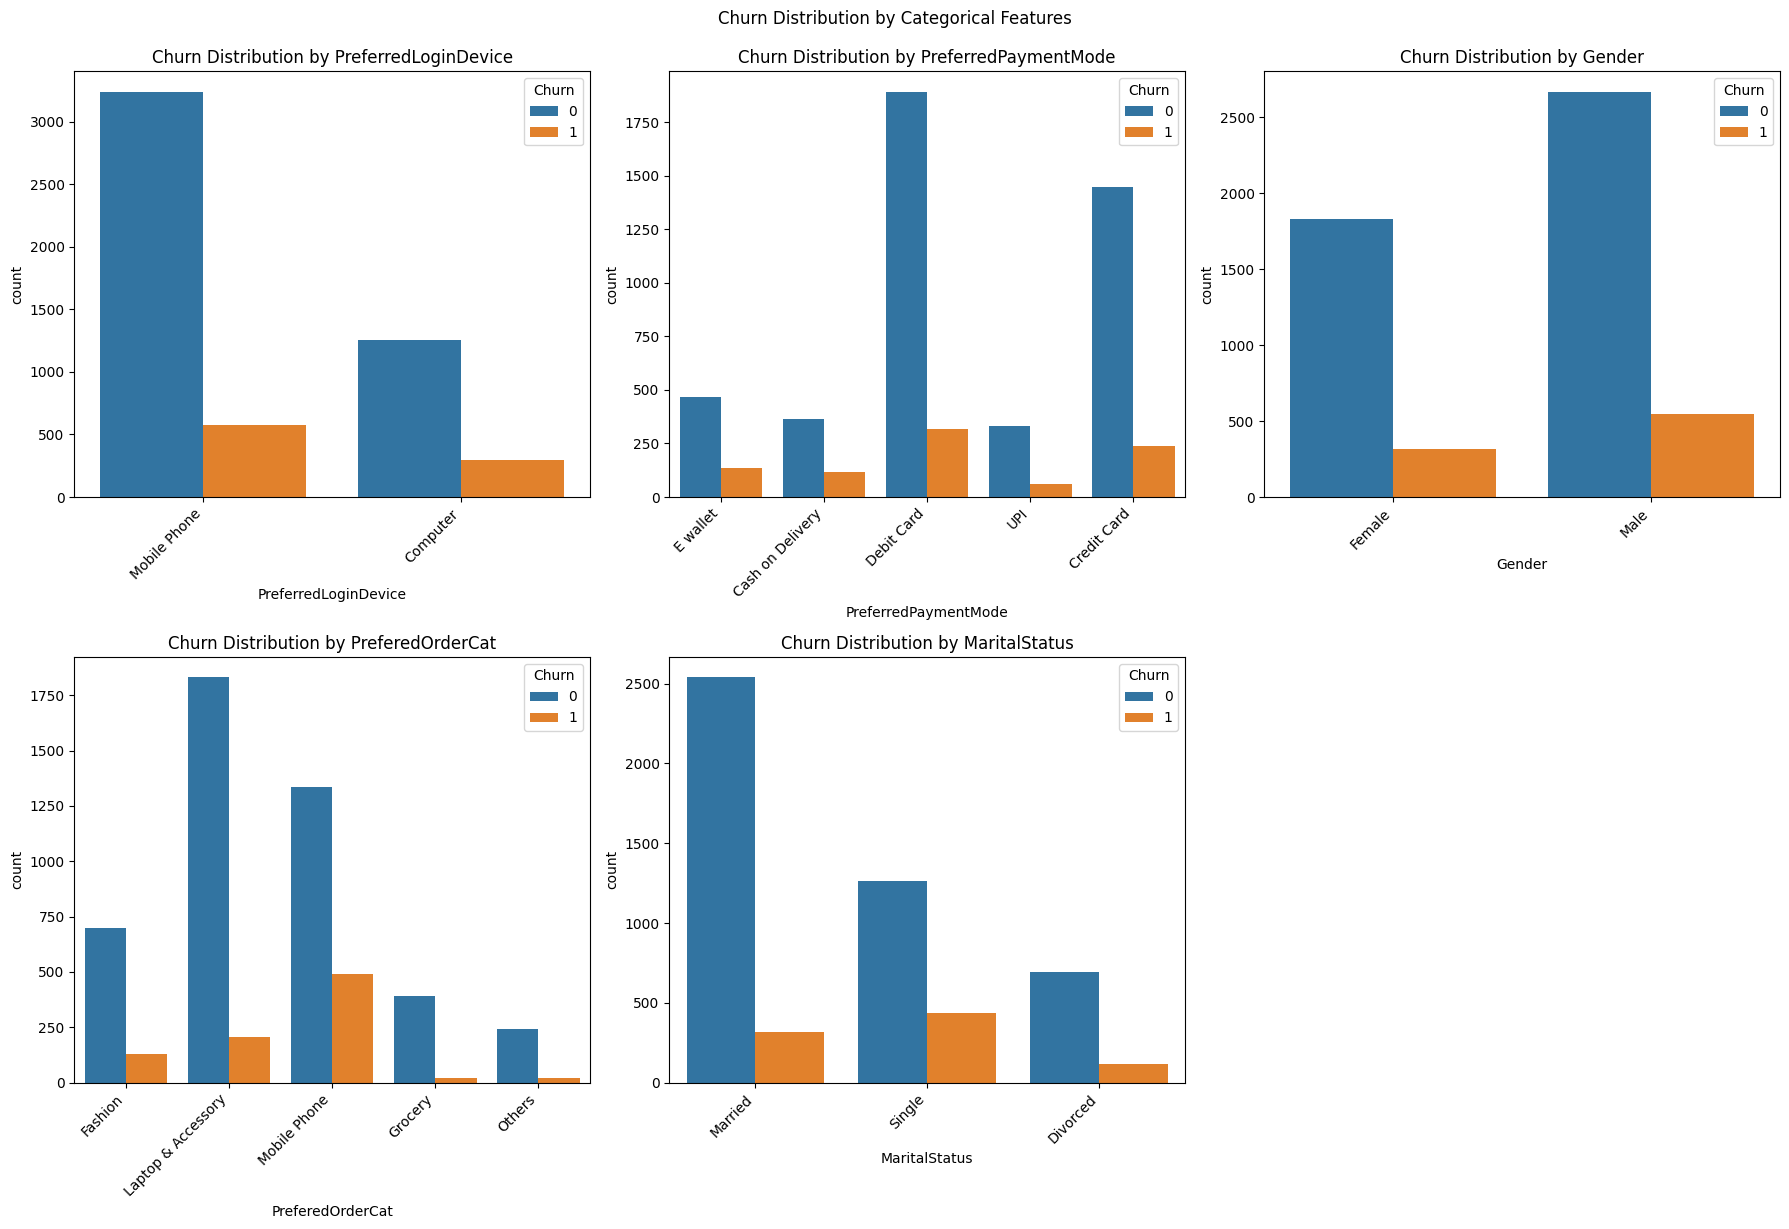

In [ ]:
categorical_cols = data.select_dtypes(include=["object"]).columns
cat_cols_count = len(categorical_cols)
cat_rows = (cat_cols_count + 2) // 3

plt.figure(figsize=(18, 6 * max(cat_rows, 1)))
for i, col in enumerate(categorical_cols):
    plt.subplot(cat_rows, 3, i + 1)
    sns.countplot(x=col, data=data, hue="Churn")
    plt.title(f"Churn Distribution by {col}")
    plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.suptitle("Churn Distribution by Categorical Features", y=1.02)
plt.show()



EDA insights and recommendations:

1. Preferred Login Device
Insight:
Most customers log in using mobile phones, and churn rates appear similar across device groups.
Recommendation:
Prioritize mobile app optimization, including mobile UX/UI, speed, personalization, loyalty programs, and push notifications.

2. Preferred Payment Mode
Insight:
Debit Card is the most common payment method, but churn appears across different payment methods.
Recommendation:
Payment mode may not be the only churn driver. Further analysis should compare transaction value and purchase frequency by payment method. Payment-based incentives such as cashback or reward points can also be tested.

3. Gender
Insight:
Male customers account for a larger share of the dataset, and churn is also concentrated among male customers.
Recommendation:
Design retention campaigns for male customers, such as offers for technology, sports, or convenience-related products. If female customers show stronger loyalty, they can be considered a potential growth segment.

4. Preferred Order Category
Insight:
Laptop & Accessory and Mobile Phone are major product categories, and their churn rates appear lower or similar compared with other categories.
Recommendation:
Strengthen cross-selling between these categories, such as phone purchases with accessory vouchers. Improve after-sales services for high-value products to maintain loyalty.

5. Marital Status
Insight:
Married customers account for the largest group, and churn is also concentrated in this segment.
Recommendation:
Develop family-oriented promotions, couple/family bundles, and personalized email marketing based on customer life stage.



## 3. Feature Engineering And Preprocessing


### 3.1 Multicollinearity check using VIF


In [ ]:
numeric_cols = data.select_dtypes(include=["int64", "float64"]).columns
X_vif = data[numeric_cols].drop(columns=["Churn"], errors="ignore")

vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(len(X_vif.columns))]

print("\nVIF results:")
print(vif_data.sort_values("VIF", ascending=False))



VIF results:
                     Feature        VIF
10            CashbackAmount  18.471436
2             HourSpendOnApp  16.826899
3   NumberOfDeviceRegistered  14.136308
4          SatisfactionScore   5.326693
5            NumberOfAddress   4.166687
1                   CityTier   4.033949
8                 OrderCount   4.024498
9          DaySinceLastOrder   3.374673
0                     Tenure   3.331700
7                 CouponUsed   3.261841
6                   Complain   1.390904


### 3.2 Check unique values


In [ ]:
print("\nNumber of unique values by column:")
print(data.nunique())



Number of unique values by column:
Churn                          2
Tenure                        36
PreferredLoginDevice           2
CityTier                       3
PreferredPaymentMode           5
Gender                         2
HourSpendOnApp                 6
NumberOfDeviceRegistered       6
PreferedOrderCat               5
SatisfactionScore              5
MaritalStatus                  3
NumberOfAddress               14
Complain                       2
CouponUsed                    17
OrderCount                    16
DaySinceLastOrder             22
CashbackAmount              2466
dtype: int64


### 3.3 One-hot encoding for categorical variables


In [ ]:
cols_to_encode = [
    "PreferredLoginDevice",
    "PreferredPaymentMode",
    "Gender",
    "PreferedOrderCat",
    "MaritalStatus"
]

df_encoded = pd.get_dummies(data, columns=cols_to_encode, drop_first=True)

print("\nEncoded data preview:")
print(df_encoded.head())
print("\nEncoded data shape:", df_encoded.shape)



Encoded data preview:
   Churn  Tenure  CityTier  HourSpendOnApp  NumberOfDeviceRegistered  \
0      0    20.0         3             4.0                         4   
1      0    13.0         1             4.0                         4   
2      0    16.0         3             3.0                         4   
3      0     5.0         1             3.0                         4   
4      0     9.0         1             3.0                         4   

   SatisfactionScore  NumberOfAddress  Complain  CouponUsed  OrderCount  ...  \
0                  5                3         0         5.0        16.0  ...   
1                  3                2         0        11.0         2.0  ...   
2                  3                3         0         5.0        12.0  ...   
3                  4                3         0         2.0         2.0  ...   
4                  2                3         1         1.0         2.0  ...   

   PreferredPaymentMode_Debit Card  PreferredPaymentMode_E wall

## 4. Supervised Learning: Churn Prediction


### 4.1 Define features and target label


In [ ]:
X = df_encoded.drop("Churn", axis=1)
y = df_encoded["Churn"]


### 4.2 Split data into training and testing sets


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=40,
    stratify=y
)

print("\nNumber of records in training set:", len(X_train))
print("Number of records in testing set:", len(X_test))



Number of records in training set: 4292
Number of records in testing set: 1074


### 4.3 Normalize numerical float features using MinMaxScaler


In [ ]:
scaler = MinMaxScaler()
float_cols = X_train.select_dtypes(include=["float64"]).columns

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[float_cols] = scaler.fit_transform(X_train[float_cols])
X_test_scaled[float_cols] = scaler.transform(X_test[float_cols])


## 5. Model Evaluation And Feature Importance


### 5.1 Hyperparameter tuning using GridSearchCV


In [ ]:
base_rf = RandomForestClassifier(random_state=40)

param_grid = {
    "n_estimators": [10, 50, 100, 200],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "bootstrap": [True, False]
}

grid_search = GridSearchCV(
    estimator=base_rf,
    param_grid=param_grid,
    cv=5,
    scoring="balanced_accuracy",
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

print("\nBest parameters:", grid_search.best_params_)

best_rf = grid_search.best_estimator_
y_pred_train = best_rf.predict(X_train_scaled)
y_pred_test = best_rf.predict(X_test_scaled)

print("\nTraining balanced accuracy:", balanced_accuracy_score(y_train, y_pred_train))
print("Testing balanced accuracy:", balanced_accuracy_score(y_test, y_pred_test))
print("\nClassification report on test set:")
print(classification_report(y_test, y_pred_test))
print("\nConfusion matrix on test set:")
print(confusion_matrix(y_test, y_pred_test))



Best parameters: {'bootstrap': False, 'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

Training balanced accuracy: 1.0
Testing balanced accuracy: 0.9282567049808429

Classification report on test set:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       900
           1       0.97      0.86      0.91       174

    accuracy                           0.97      1074
   macro avg       0.97      0.93      0.95      1074
weighted avg       0.97      0.97      0.97      1074


Confusion matrix on test set:
[[895   5]
 [ 24 150]]


### 5.2 Feature importance analysis


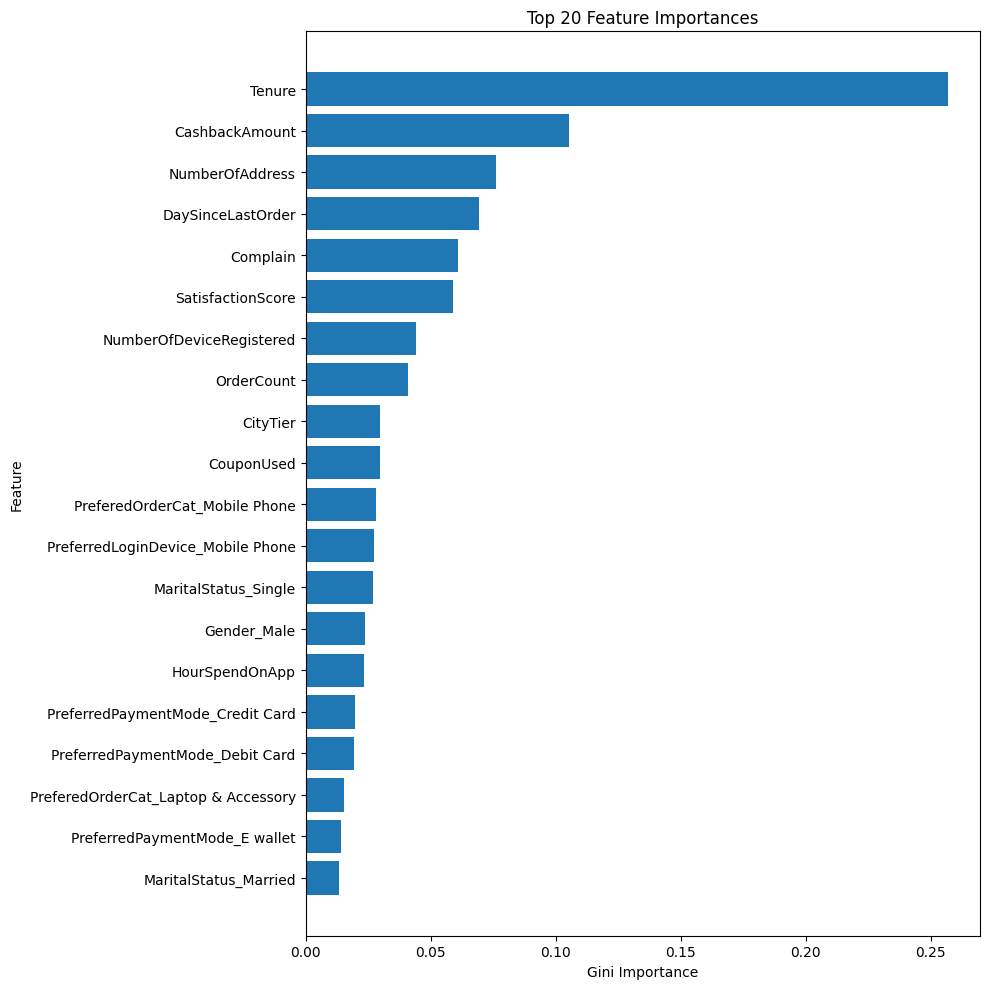

In [ ]:
feature_importance = pd.DataFrame({
    "Feature": X_train_scaled.columns,
    "Gini Importance": best_rf.feature_importances_
}).sort_values("Gini Importance", ascending=True)

plt.figure(figsize=(10, 10))
plt.barh(feature_importance.tail(20)["Feature"], feature_importance.tail(20)["Gini Importance"])
plt.title("Top 20 Feature Importances")
plt.xlabel("Gini Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


## 6. Unsupervised Learning: Churned Customer Segmentation


Business question:
Based on the behavior of churned customers, the company wants to create special promotions for them.
The objective is to segment churned customers into meaningful groups and identify differences between these groups.


### 6.1 Filter churned customers only


In [ ]:
dummies_df = df_encoded[df_encoded["Churn"] == 1].copy()


### 6.2 Drop selected columns for clustering based on project scope


In [ ]:
# Define the list of columns to be dropped for clustering.
# These are columns that the user explicitly chose not to include in the clustering, or are redundant/target-related.
cols_to_drop_for_clustering = [
    "HourSpendOnApp", # Excluded as per user request
    "PreferredLoginDevice_Mobile Phone", # Excluded as per user request
    "PreferredLoginDevice_Phone", # Excluded as per user request
    "PreferredPaymentMode_COD", # Excluded as per user request
    "PreferredPaymentMode_Cash on Delivery", # Excluded as per user request
    "PreferredPaymentMode_Credit Card", # Excluded as per user request
    "PreferredPaymentMode_Debit Card", # Excluded as per user request
    "PreferredPaymentMode_E wallet", # Excluded as per user request
    "PreferredPaymentMode_UPI", # Excluded as per user request
    "Gender_Male", # Excluded as per user request
    "PreferedOrderCat_Grocery", # Excluded as per user request
    "PreferedOrderCat_Laptop & Accessory", # Excluded as per user request
    "PreferedOrderCat_Mobile", # Excluded as per user request
    "PreferedOrderCat_Mobile Phone", # Excluded as per user request
    "PreferedOrderCat_Others", # Excluded as per user request
    "MaritalStatus_Married", # Excluded as per user request
    "MaritalStatus_Single" # Excluded as per user request
]

# Drop the specified columns from the DataFrame.
# The 'errors="ignore"' argument ensures that the code doesn't fail if a column is not found,
# which can happen due to one-hot encoding dropping the first category.
cluster_df = dummies_df.drop(columns=cols_to_drop_for_clustering, errors="ignore")

In [ ]:
# Drop target column before clustering if it exists.
cluster_features = cluster_df.drop(columns=["Churn"], errors="ignore")


### 6.3 PCA for dimensionality reduction


In [ ]:
pca = PCA(n_components=3, random_state=40)
PCA_ds = pd.DataFrame(
    pca.fit_transform(cluster_features),
    columns=["PC1", "PC2", "PC3"],
    index=cluster_features.index
)

print("\nExplained variance ratio for 3 PCA components:")
print(pca.explained_variance_ratio_)



Explained variance ratio for 3 PCA components:
[0.96291814 0.0169633  0.00885472]


### 6.4 Check cumulative explained variance by number of PCA components


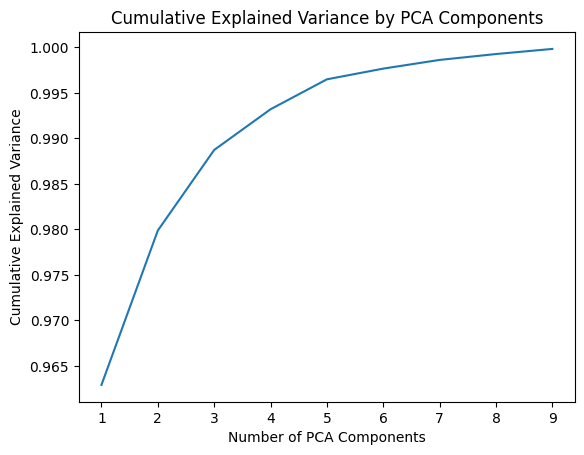

In [ ]:
explained_variance = []
max_components = min(9, cluster_features.shape[1])

for i in range(1, max_components + 1):
    pca_temp = PCA(n_components=i, random_state=40)
    pca_temp.fit(cluster_features)
    explained_variance.append(sum(pca_temp.explained_variance_ratio_))

sns.lineplot(x=list(range(1, max_components + 1)), y=explained_variance)
plt.title("Cumulative Explained Variance by PCA Components")
plt.xlabel("Number of PCA Components")
plt.ylabel("Cumulative Explained Variance")
plt.show()


### 6.5 Choose K using the Elbow Method


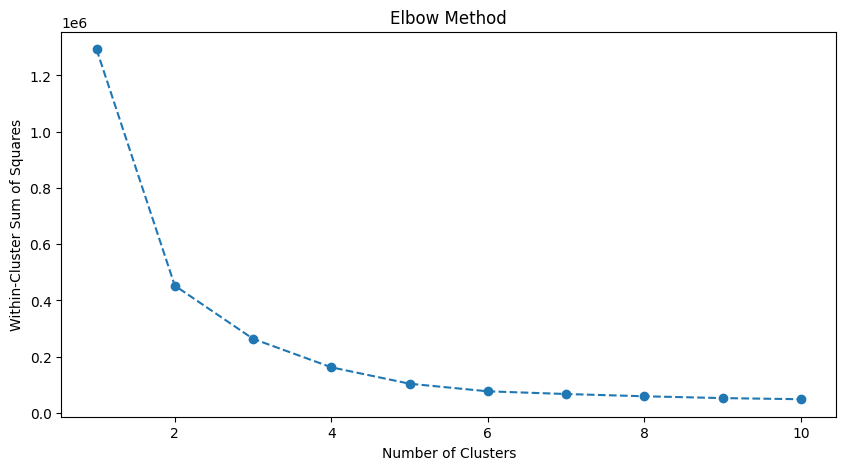

In [ ]:
sum_of_squared_distances = []
max_clusters = 10

for i in range(1, max_clusters + 1):
    kmeans = KMeans(n_clusters=i, init="k-means++", random_state=40, n_init=10)
    kmeans.fit(PCA_ds)
    sum_of_squared_distances.append(kmeans.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(range(1, max_clusters + 1), sum_of_squared_distances, marker="o", linestyle="--")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Within-Cluster Sum of Squares")
plt.show()





Based on the Elbow Method, k = 3 is selected.


### 6.6 Apply K-Means clustering


In [ ]:
kmeans = KMeans(n_clusters=3, init="k-means++", random_state=40, n_init=10)
predicted_labels = kmeans.fit_predict(PCA_ds)

PCA_ds["Cluster"] = predicted_labels
dummies_df["Cluster"] = predicted_labels

print("\nClustered churned customer data information:")
dummies_df.info()



Clustered churned customer data information:
<class 'pandas.core.frame.DataFrame'>
Index: 867 entries, 7 to 5596
Data columns (total 25 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Churn                                867 non-null    int64  
 1   Tenure                               867 non-null    float64
 2   CityTier                             867 non-null    int64  
 3   HourSpendOnApp                       867 non-null    float64
 4   NumberOfDeviceRegistered             867 non-null    int64  
 5   SatisfactionScore                    867 non-null    int64  
 6   NumberOfAddress                      867 non-null    int64  
 7   Complain                             867 non-null    int64  
 8   CouponUsed                           867 non-null    float64
 9   OrderCount                           867 non-null    float64
 10  DaySinceLastOrder                    867 non-null    flo

### 6.7 Evaluate clustering quality using Silhouette Score


In [ ]:
sil_score = silhouette_score(PCA_ds[["PC1", "PC2", "PC3"]], predicted_labels)
print("\nSilhouette Score:", sil_score)



Silhouette Score: 0.6117471959171082


## 7. Cluster Profiling


### 7.1 Cluster size


In [ ]:
print("\nCluster size:")
print(dummies_df["Cluster"].value_counts())

print("\nCluster percentage:")
print((dummies_df["Cluster"].value_counts(normalize=True) * 100).round(2))



Cluster size:
Cluster
0    623
2    214
1     30
Name: count, dtype: int64

Cluster percentage:
Cluster
0    71.86
2    24.68
1     3.46
Name: proportion, dtype: float64


### 7.2 Mean values of numerical variables by cluster


In [ ]:
num_cols_for_profile = [
    "Tenure",
    "CashbackAmount",
    "NumberOfAddress",
    "DaySinceLastOrder",
    "Complain",
    "SatisfactionScore",
    "NumberOfDeviceRegistered",
    "OrderCount",
    "CouponUsed",
    "CityTier",
    "HourSpendOnApp"
]

available_num_cols = [col for col in num_cols_for_profile if col in dummies_df.columns]
print("\nAverage numerical values by cluster:")
print(dummies_df.groupby("Cluster")[["Churn"] + available_num_cols].mean().round(2))


Average numerical values by cluster:
         Churn  Tenure  CashbackAmount  NumberOfAddress  DaySinceLastOrder  \
Cluster                                                                      
0          1.0    2.22          144.99             4.27               2.74   
1          1.0   11.73          291.22             5.40               8.60   
2          1.0    5.60          202.21             5.32               4.60   

         Complain  SatisfactionScore  NumberOfDeviceRegistered  OrderCount  \
Cluster                                                                      
0            0.54               3.39                      3.94        2.36   
1            0.67               3.53                      4.07        7.13   
2            0.48               3.30                      4.04        4.07   

         CouponUsed  CityTier  HourSpendOnApp  
Cluster                                        
0              1.49      1.67            2.98  
1              3.20      2.07       

### 7.3 Boxplots for numerical variables by cluster


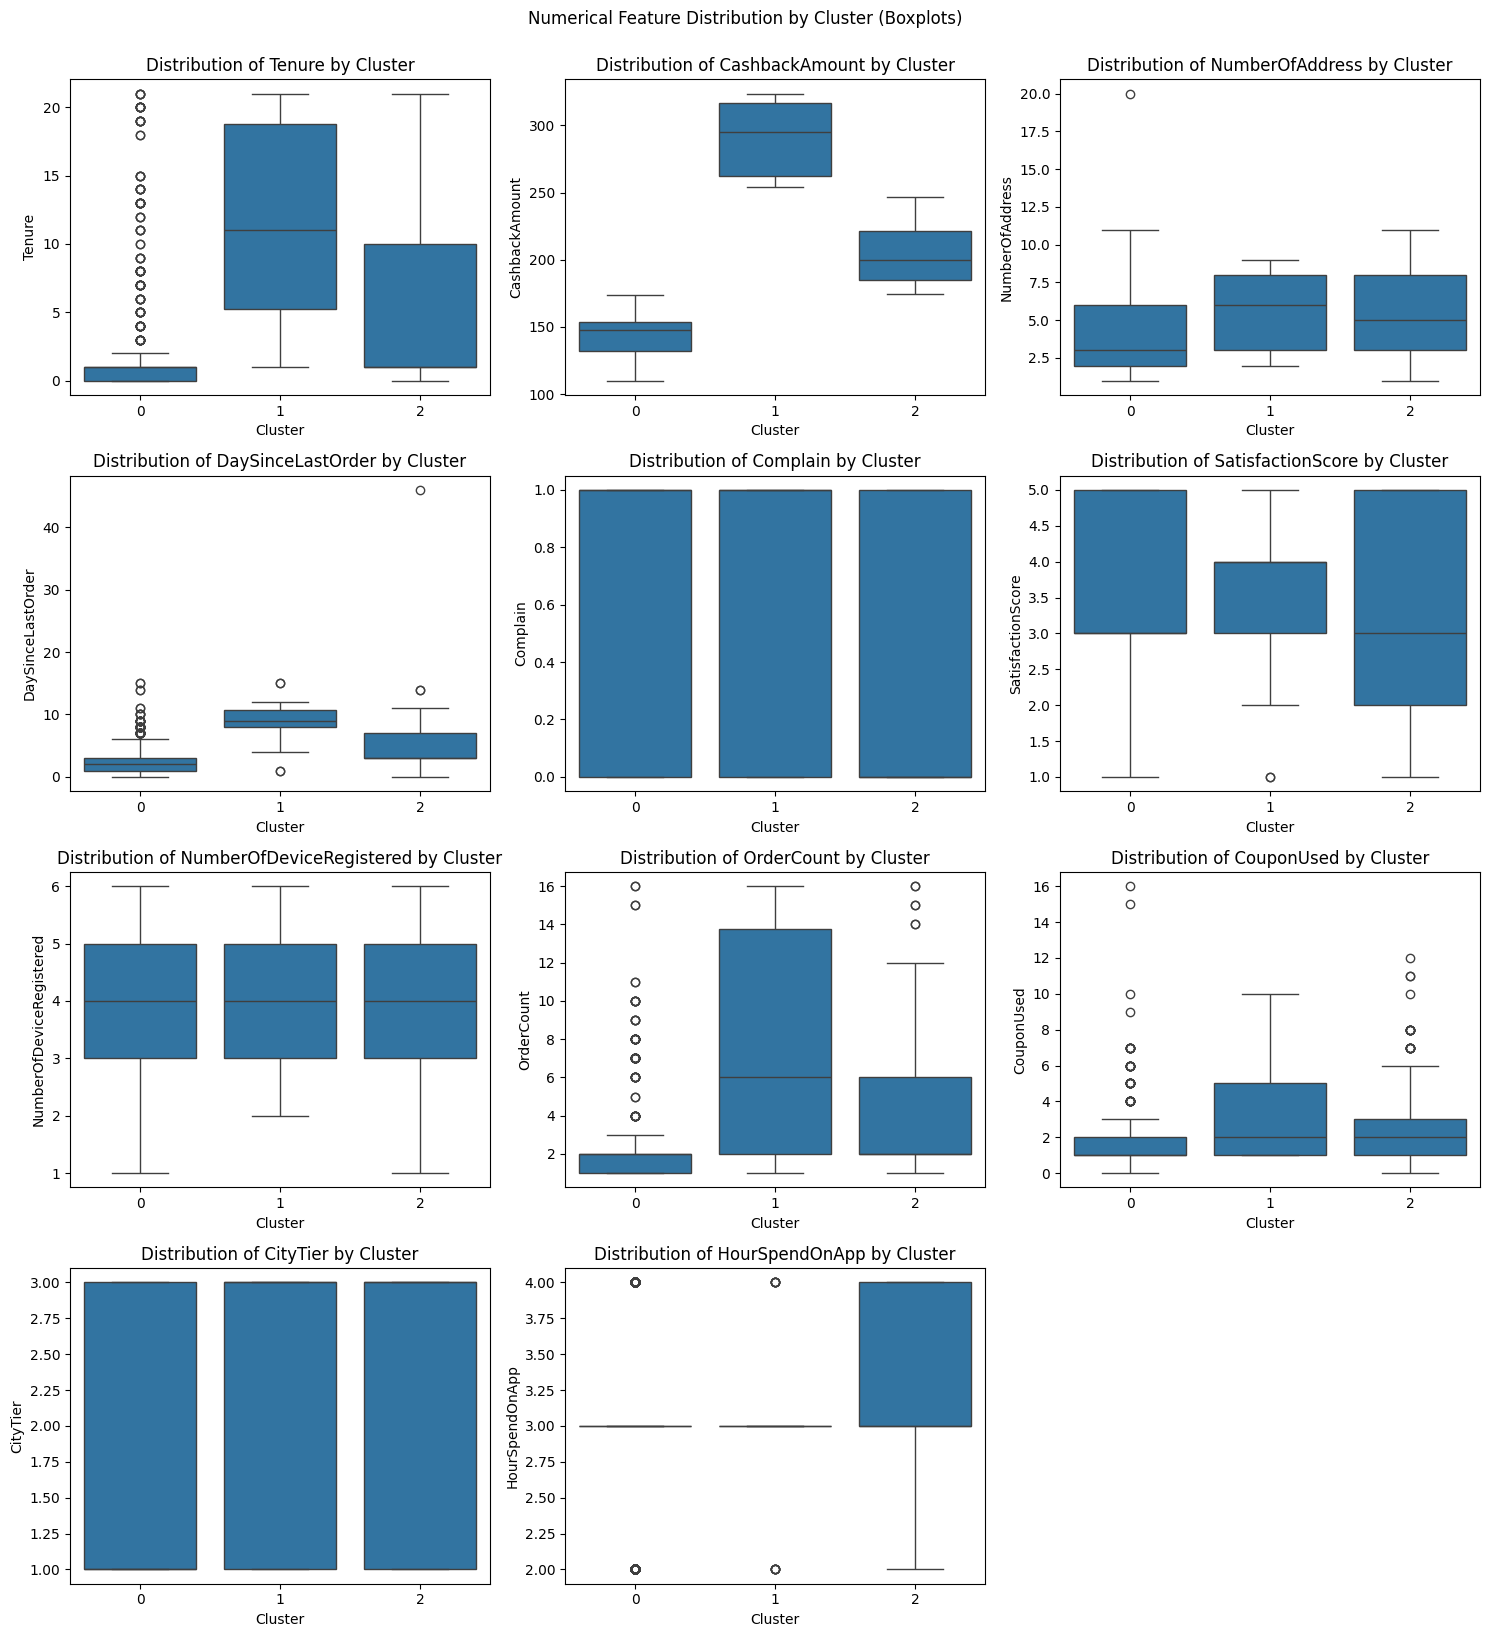

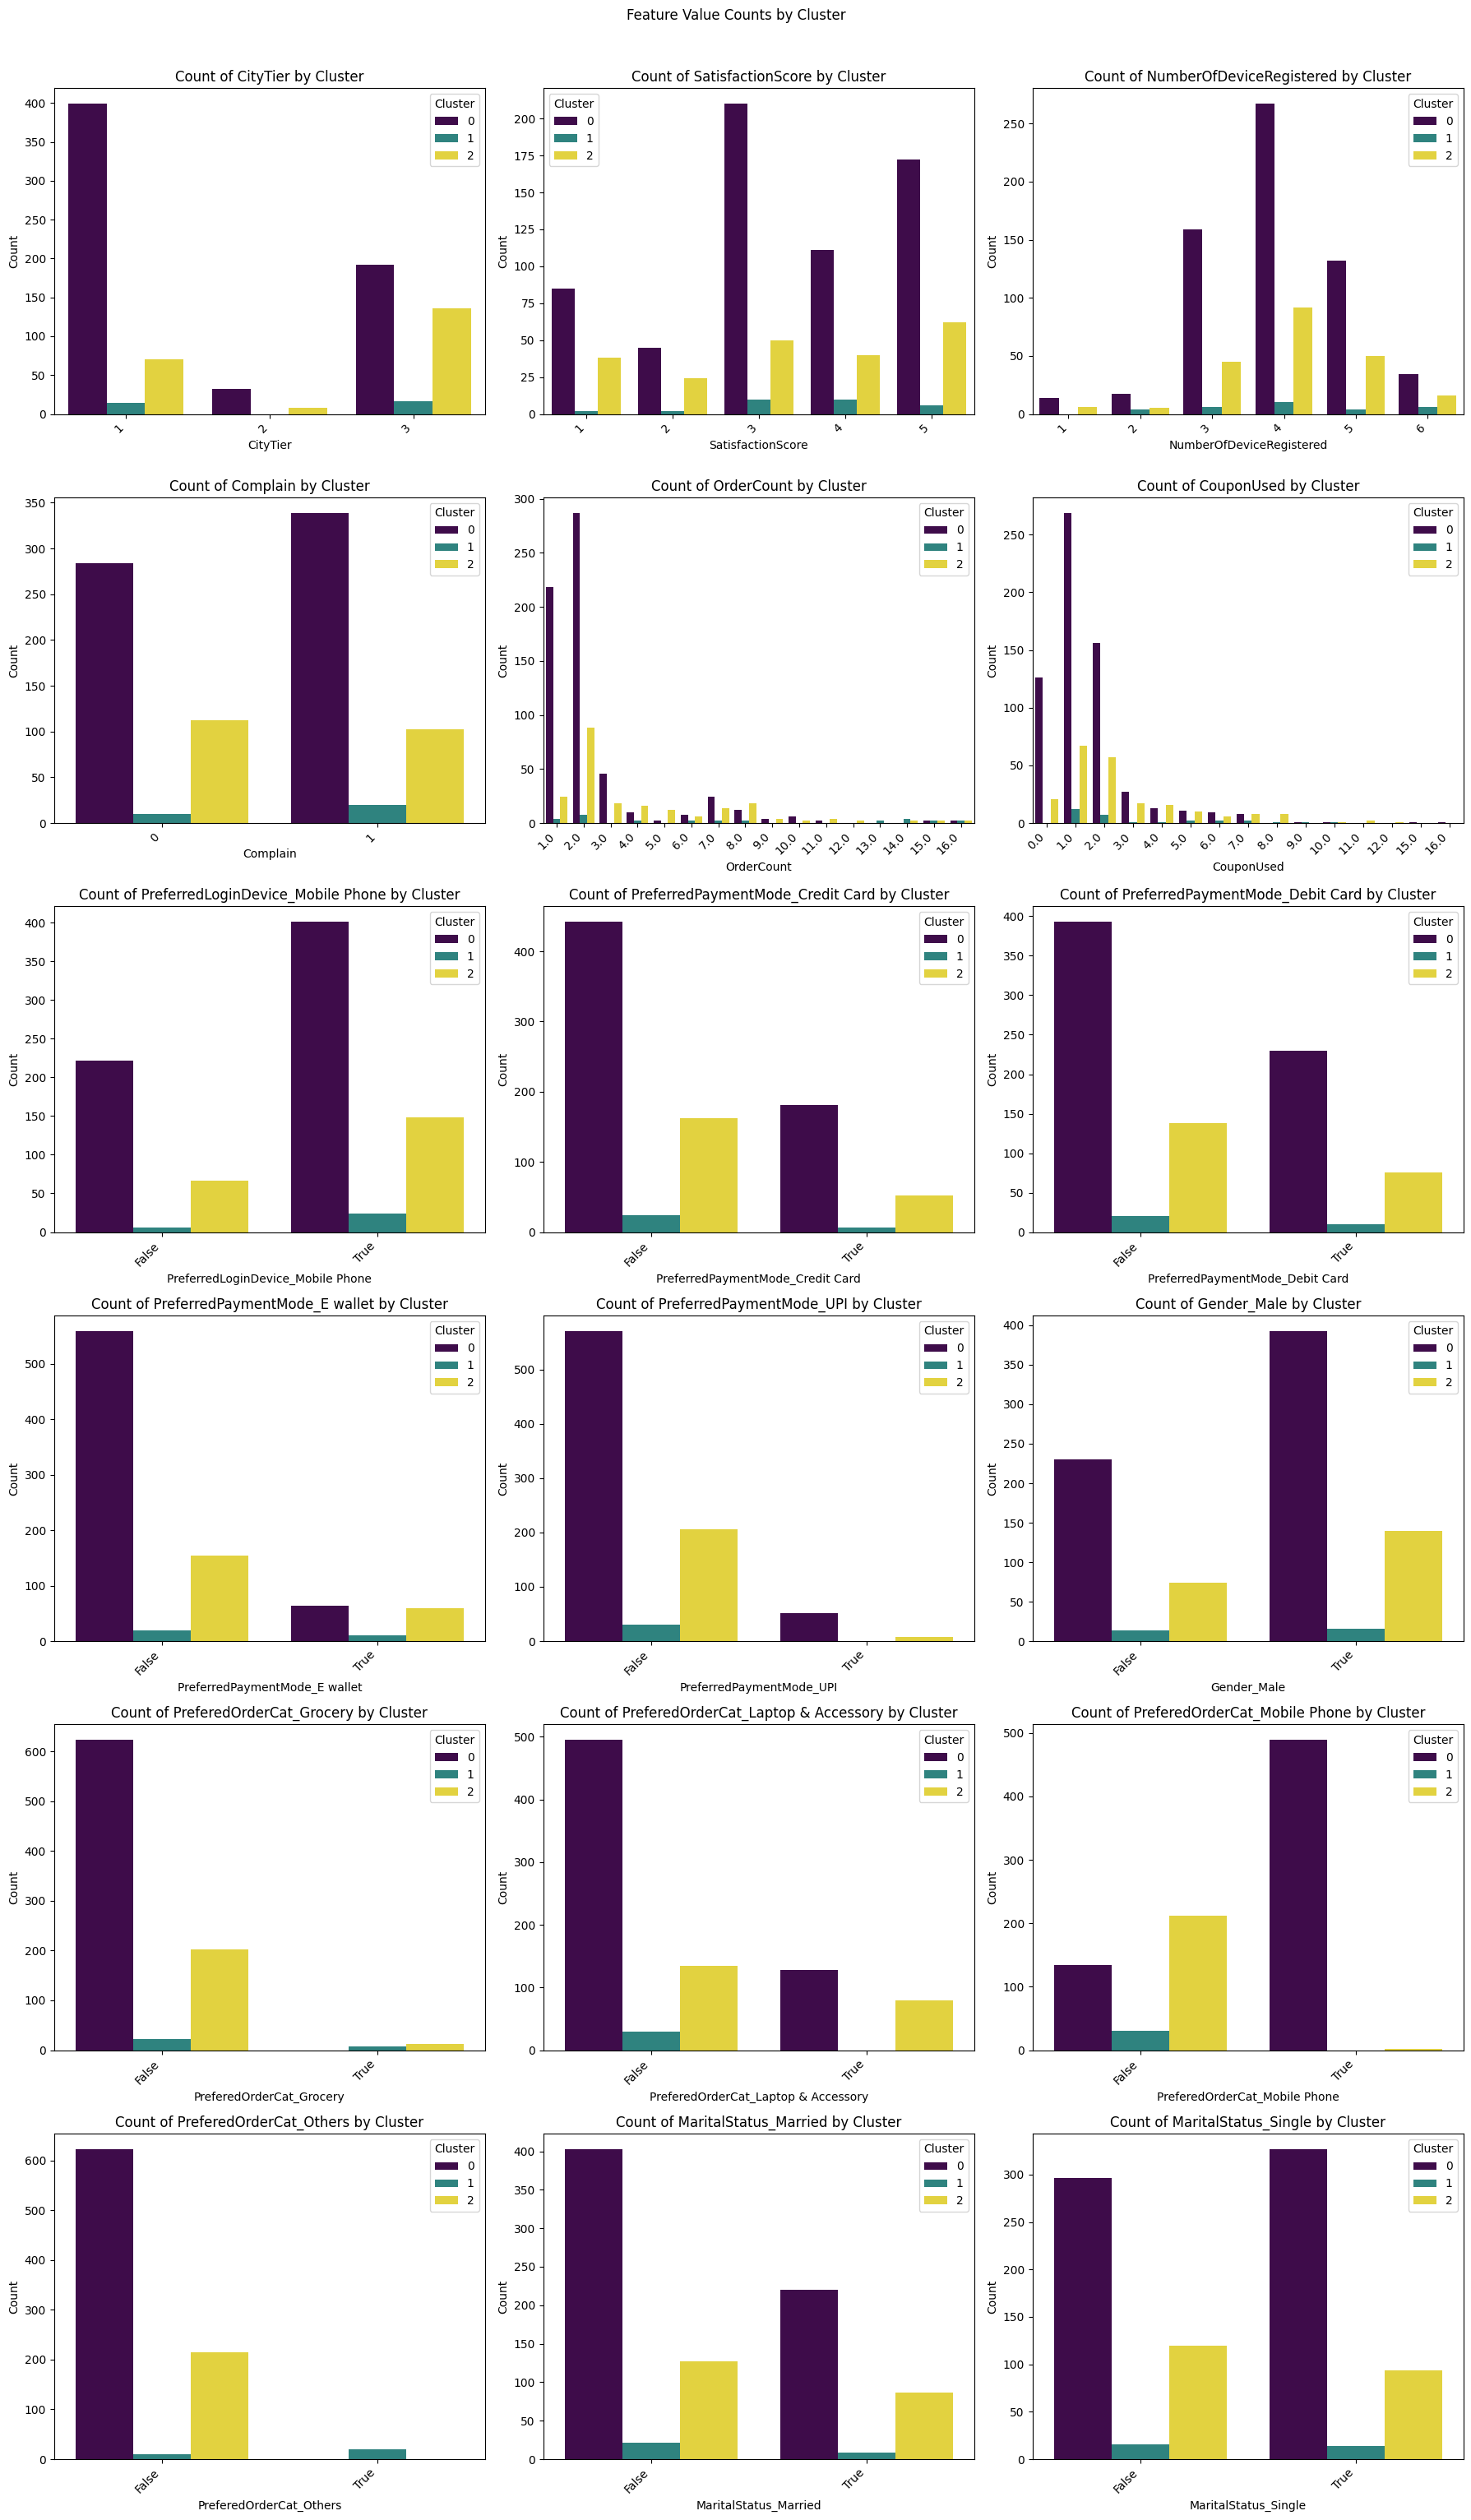

In [ ]:
num_features = len(available_num_cols)
num_cols_plot = 3
num_rows_plot = (num_features + num_cols_plot - 1) // num_cols_plot

plt.figure(figsize=(num_cols_plot * 5, num_rows_plot * 4))
for i, col in enumerate(available_num_cols):
    plt.subplot(num_rows_plot, num_cols_plot, i + 1)
    sns.boxplot(data=dummies_df, x="Cluster", y=col)
    plt.title(f"Distribution of {col} by Cluster")
    plt.xlabel("Cluster")
    plt.ylabel(col)

plt.tight_layout()
plt.suptitle("Numerical Feature Distribution by Cluster (Boxplots)", y=1.02)
plt.show()

# Prepare for count plots for discrete/categorical features
discrete_features_for_counts = [
    "CityTier", "SatisfactionScore", "NumberOfDeviceRegistered",
    "Complain", "OrderCount", "CouponUsed"
]

# Filter to include only features actually present in dummies_df
discrete_features_for_counts = [col for col in discrete_features_for_counts if col in dummies_df.columns]

# Add boolean/one-hot encoded columns to the list for count plots
# Filter out 'Churn' if it accidentally gets included, as it's the target for segmentation.
bool_cols_for_counts = [col for col in dummies_df.select_dtypes(include=["bool"]).columns.tolist() if col != 'Churn']

features_to_plot_counts = discrete_features_for_counts + bool_cols_for_counts

if features_to_plot_counts:
    num_features_counts = len(features_to_plot_counts)
    num_cols_plot_counts = 3
    num_rows_plot_counts = (num_features_counts + num_cols_plot_counts - 1) // num_cols_plot_counts

    plt.figure(figsize=(num_cols_plot_counts * 6, num_rows_plot_counts * 5))
    for i, col in enumerate(features_to_plot_counts):
        plt.subplot(num_rows_plot_counts, num_cols_plot_counts, i + 1)
        sns.countplot(data=dummies_df, x=col, hue="Cluster", palette="viridis")
        plt.title(f"Count of {col} by Cluster")
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.suptitle("Feature Value Counts by Cluster", y=1.02)
    plt.show()
else:
    print("No discrete or boolean features available for count plots.")

The clustering result shows that Cluster 0 is the dominant customer segment, representing the majority of observations across most features. Customers in this cluster are commonly associated with CityTier 1 and CityTier 3, moderate-to-high satisfaction scores, 3–5 registered devices, low order frequency, and frequent preference for the Mobile Phone category. Cluster 2 is a smaller but meaningful segment, more visible in CityTier 3 and less associated with the Mobile Phone product category. Cluster 1 contains very few customers, suggesting a niche or outlier segment. Overall, the clusters mainly differ by customer volume, city tier, preferred product category, device usage, and purchasing behavior. However, percentage-based comparison is recommended because raw counts are strongly affected by the unequal cluster sizes.

### 7.4 Boolean / one-hot encoded feature profile by cluster


In [ ]:
bool_cols = dummies_df.select_dtypes(include=["bool"]).columns.tolist()
print("\nBoolean / one-hot encoded columns:")
print(bool_cols)

if bool_cols:
    bool_profile = dummies_df.groupby("Cluster")[bool_cols].mean() * 100
    print("\nProportion of True values for boolean features by cluster:")
    print(bool_profile.round(2))

    detailed_bool_profile_data = {}
    for col in bool_cols:
        true_percentages = bool_profile[col]
        false_percentages = 100 - true_percentages
        detailed_bool_profile_data[f"{col}_True (%)"] = true_percentages
        detailed_bool_profile_data[f"{col}_False (%)"] = false_percentages

    detailed_bool_profile = pd.DataFrame(detailed_bool_profile_data).round(2)
    print("\nDetailed True/False percentage breakdown by cluster:")
    print(detailed_bool_profile)



Boolean / one-hot encoded columns:
['PreferredLoginDevice_Mobile Phone', 'PreferredPaymentMode_Credit Card', 'PreferredPaymentMode_Debit Card', 'PreferredPaymentMode_E wallet', 'PreferredPaymentMode_UPI', 'Gender_Male', 'PreferedOrderCat_Grocery', 'PreferedOrderCat_Laptop & Accessory', 'PreferedOrderCat_Mobile Phone', 'PreferedOrderCat_Others', 'MaritalStatus_Married', 'MaritalStatus_Single']

Proportion of True values for boolean features by cluster:
         PreferredLoginDevice_Mobile Phone  PreferredPaymentMode_Credit Card  \
Cluster                                                                        
0                                    64.37                             29.05   
1                                    80.00                             20.00   
2                                    69.16                             24.30   

         PreferredPaymentMode_Debit Card  PreferredPaymentMode_E wallet  \
Cluster                                                            

### 7.5 Count churned customers by cluster


In [ ]:
cluster_col = "Cluster"
churn_col = "Churn"

bubble_df = (
    dummies_df.groupby([cluster_col, churn_col])
    .size()
    .reset_index(name="Count")
)

print("\nNumber of churned customers per cluster:")
print(bubble_df)



Number of churned customers per cluster:
   Cluster  Churn  Count
0        0      1    623
1        1      1     30
2        2      1    214


### 7.6 Optional validation: train a classifier to explain cluster assignment


In [ ]:
X_k = dummies_df.drop(columns=["Cluster"], errors="ignore")
y_k = dummies_df["Cluster"]

X_k_train, X_k_test, y_k_train, y_k_test = train_test_split(
    X_k,
    y_k,
    test_size=0.5,
    random_state=42,
    stratify=y_k
)

cluster_rf = RandomForestClassifier(max_depth=15, random_state=40, n_estimators=100)
cluster_rf.fit(X_k_train, y_k_train)
y_k_pred = cluster_rf.predict(X_k_test)

cluster_balanced_accuracy = balanced_accuracy_score(y_k_test, y_k_pred)
print("\nBalanced accuracy for cluster explanation model:", cluster_balanced_accuracy)



Balanced accuracy for cluster explanation model: 0.9937694704049843


## 8. Business Insights And Recommendations



Based on the clustering result and churn distribution, customers can be divided into three main behavioral segments: **Cluster 0, Cluster 1, and Cluster 2**.

The churned customer count by cluster is:

- **Cluster 0:** 605 churned customers
- **Cluster 1:** 228 churned customers
- **Cluster 2:** 34 churned customers

> Note: These values represent the **number of churned customers**, not the churn rate. To calculate the churn rate for each cluster, the total number of customers in each cluster is required. However, based on the churn count, Cluster 0 has the largest churn volume and should be prioritized from a business perspective.

---

### 1. Cluster 0: New / Low-Engagement Customers

Cluster 0 appears to represent **new or low-engagement customers**.

From the feature distribution:

- Tenure is very low, mostly around 0–2 months.
- OrderCount is low, mostly around 1–2 orders.
- CouponUsed is relatively low.
- CashbackAmount is the lowest among the three clusters.
- DaysSinceLastOrder is also low, meaning many customers recently placed an order.
- This cluster has the highest number of churned customers, with **605 churned customers**.

#### Business Insight

Customers in Cluster 0 are likely new customers or first-time buyers who have not yet developed a strong purchasing habit. Although some customers recently placed an order, many of them churn early, which suggests that the business may not be successfully converting new customers into repeat customers.

This segment is important because a high churn count in early-stage customers may reduce the return on customer acquisition cost.

#### Business Recommendations

The main strategy for Cluster 0 should be **activation and early retention**.

Recommended actions:

- Create a second-purchase incentive campaign.
  - Example: offer a discount or cashback voucher for the next order within 7 days.
- Improve the onboarding experience for new customers.
  - Example: guide customers to popular products, personalized recommendations, and app features.
- Send personalized push notifications or emails after the first order.
  - Example: recommend products related to the first purchase.
- Reduce friction in the purchasing journey.
  - Example: simplify checkout, improve search, and remind customers about abandoned carts.

#### Suggested KPIs

- Second purchase rate
- 7-day repeat purchase rate
- 14-day repeat purchase rate
- New customer churn rate
- Conversion rate from first order to second order

---

### 2. Cluster 1: Growing / Medium-Engagement Customers

Cluster 1 appears to represent **medium-engagement customers with growth potential**.

From the feature distribution:

- Tenure is higher than Cluster 0 but lower than Cluster 2.
- OrderCount is moderate, usually around 2–5 orders.
- CouponUsed is moderate.
- CashbackAmount is also moderate.
- HourSpendOnApp tends to be higher than the other clusters.
- This cluster has **228 churned customers**, which is lower than Cluster 0 but still significant.

#### Business Insight

Customers in Cluster 1 have already shown some level of engagement with the platform. They spend time on the app, make repeat purchases, and use coupons. However, they are not yet fully loyal customers.

This segment is valuable because these customers can potentially be moved into Cluster 2 if the business successfully increases their purchase frequency and engagement.

#### Business Recommendations

The main strategy for Cluster 1 should be **retention and growth**.

Recommended actions:

- Build a loyalty program with different membership tiers.
  - Example: Bronze, Silver, and Gold levels based on purchase frequency or spending.
- Use personalized product recommendations.
  - Example: recommend complementary products based on purchase history.
- Run targeted campaigns to increase purchase frequency.
  - Example: send a limited-time voucher if the customer has not ordered for several days.
- Offer bundle deals or cross-sell campaigns.
  - Example: recommend product bundles to increase average order value.
- Use cashback incentives carefully to encourage repeat purchase without over-discounting.

#### Suggested KPIs

- Repeat purchase rate
- Order frequency
- Average order value
- Coupon redemption rate
- Customer movement from Cluster 1 to Cluster 2
- Churn rate of medium-engagement customers

---

### 3. Cluster 2: Loyal / High-Value Customers

Cluster 2 appears to represent **loyal and high-value customers**.

From the feature distribution:

- Tenure is the highest among the three clusters.
- OrderCount is also the highest.
- CouponUsed is relatively high.
- CashbackAmount is the highest among all clusters.
- DaysSinceLastOrder is slightly higher, which may indicate a longer purchase cycle.
- This cluster has the lowest number of churned customers, with only **34 churned customers**.

#### Business Insight

Customers in Cluster 2 are the most loyal and valuable segment. They have a longer relationship with the business, place more orders, and receive higher cashback amounts. Although the churn count is low, losing customers in this segment can have a large negative impact because each customer may contribute high lifetime value.

This segment should not only be retained but also used to generate additional business value through referrals and premium engagement programs.

#### Business Recommendations

The main strategy for Cluster 2 should be **loyalty maintenance and customer lifetime value maximization**.

Recommended actions:

- Create a VIP customer program.
  - Example: exclusive promotions, early access to new products, or free shipping benefits.
- Provide personalized offers instead of mass discounts.
  - Example: send offers based on the customer’s favorite product categories.
- Launch a referral program.
  - Example: reward loyal customers for referring new customers.
- Monitor customers with increasing DaysSinceLastOrder.
  - Example: send a win-back reminder when a high-value customer has not purchased within their normal purchase cycle.
- Protect profit margin by avoiding unnecessary discounts for customers who are already highly engaged.

#### Suggested KPIs

- Customer lifetime value
- VIP customer retention rate
- Revenue contribution by Cluster 2
- Referral rate
- Average order value
- Profit margin after promotions

---

## Overall Business Strategy

The three clusters suggest different business priorities:

| Cluster | Customer Type | Main Problem | Recommended Strategy |
|---|---|---|---|
| Cluster 0 | New / low-engagement customers | High churn volume and low repeat purchase | Activation and early retention |
| Cluster 1 | Medium-engagement customers | Not yet fully loyal | Retention, upselling, and loyalty building |
| Cluster 2 | Loyal / high-value customers | Low churn but high revenue impact if lost | VIP retention and CLV maximization |

---

## Key Takeaways

Cluster 0 should be the highest priority for churn reduction because it has the largest number of churned customers. The business should focus on converting new customers into repeat customers through onboarding, second-purchase incentives, and personalized engagement.

Cluster 1 should be treated as a growth segment. These customers already show purchasing potential, so the business should encourage them to buy more frequently through loyalty programs, personalized recommendations, and targeted promotions.

Cluster 2 represents the most valuable customer group. The business should focus on maintaining loyalty, increasing customer lifetime value, and encouraging referrals through VIP programs and personalized offers.

Overall, the business should avoid using the same promotion strategy for all customers. Instead, marketing and retention actions should be customized based on the customer cluster.

In [ ]:
print("\nProject workflow completed successfully.")



Project workflow completed successfully.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels
import sklearn

print("All required libraries are working!")

All required libraries are working!
